# DATA-445: Homework Assignment 8

**Instructions**

- This homework assignment is worth **88** points.
- Please submit a **.ipynb** file to Blackboard.
- **Please strive for clarity and organization.**
- **AI usage**:
  - AI use is strictly **prohibited** for conceptual exercises.
  - For applied (Python) exercises, you may use AI exclusively for **debugging**. Do not use AI to generate answers.
- **Due Date: November 13, 2026, by 11:59 PM.**

## Exercise 1 (9 points)

Principal component analysis (PCA) and linear discriminant analysis (LDA) are both linear techniques for dimensionality reduction.

**(a)** In your own words, state what objective each method optimizes, and explain why PCA is called *unsupervised* while LDA is called *supervised*.

**(b)** Describe a situation in which PCA would discard exactly the information that is most useful for classification, while LDA would keep it.

**(c)** For a classification problem with $c$ classes and $d$ features ($d > c$), what is the maximum number of linear discriminants LDA can produce? Explain why.`

*Write your answer here.*
(a) PCA finds where the most amount of variance in the data. LDA finds the where the data separates the most. PCA is call unsupervised because looks at the features and doesnt label while LDA also uses a target.

(b) PCA would discard information useful for classification if the features that help with classification have little variance but LDA would be good.

(c) LDA maximum number of linear discriminants is c-1 because you only need at most one less than the amount of classes to be able to separate them.

## Exercise 2 (5 points)

Which of the following statements about nonlinear dimensionality reduction (t-SNE and UMAP) is **TRUE**?

**A.** The distances between well-separated clusters in a t-SNE plot faithfully reflect how dissimilar the clusters are in the original feature space.

**B.** t-SNE is a linear projection, so new observations can be mapped onto an existing embedding simply by multiplying them by a fixed projection matrix.

**C.** Perplexity in t-SNE (and `n_neighbors` in UMAP) controls roughly how many neighbors each point considers, so changing it can change the apparent structure of the plot; the plot should be inspected at several settings before drawing conclusions.

**D.** Because t-SNE and UMAP are deterministic, the resulting embedding is identical regardless of the random seed.

Select one answer and justify in one or two sentences why it is correct.

*Write your answer here.*
perplexity and n_neighbor for t-sne and UMAP controls roughly how many neighbors each point considers which is true. so it would change the structure of the plot and inspected at different settings to get a conclusive setting set.

## Exercise 3 (30 points)

In this exercise you will compare PCA, LDA, and t-SNE on the wine dataset (178 wines, 13 chemical features, 3 cultivars). Load it with:

```python
from sklearn.datasets import load_wine
X, y = load_wine(return_X_y=True, as_frame=True)
```

**(a)** Split the data into 70% training and 30% test sets (use `stratify = y` and `random_state = 1`). Standardize the features using the training set only.

**(b)** Fit PCA on the standardized training data keeping all 13 components. Plot the individual and cumulative explained variance ratios. How many components are needed to explain at least 90% of the variance?

**(c)** Reduce the data to **2 components** using PCA (fit on training data) and train a logistic regression on the result. Report the training and test accuracy.

**(d)** Repeat (c) using LDA with 2 components. Report the training and test accuracy, and make a scatter plot of the transformed training data colored by class for both PCA and LDA (side by side).

**(e)** Apply t-SNE (`perplexity = 30`, `random_state = 1`) to the full standardized dataset and plot the 2D embedding colored by class.

**(f)** In 2–3 sentences, compare the three methods based on your results. Which would you use for a classifier, and which only for visualization? Why?

In [1]:
from sklearn.datasets import load_wine
X, y = load_wine(return_X_y=True, as_frame=True)

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

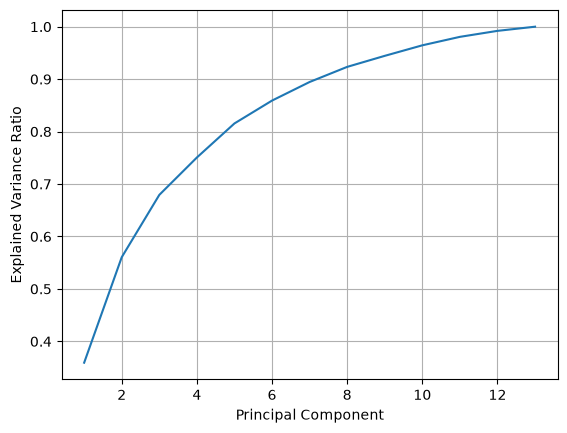

In [5]:
from sklearn.decomposition import PCA
pca = PCA(n_components=13)

pca.fit_transform(X_train_scaled)

explained_variance_ratio = pca.explained_variance_ratio_

import matplotlib.pyplot as plt

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid(True)
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_.cumsum())
plt.show()  

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

pca2 = PCA(n_components=2)

pca2.fit_transform(X_train_scaled)

X_train_pca = pca2.transform(X_train_scaled)
X_test_pca = pca2.transform(X_test_scaled)

LogisticRegression_model = LogisticRegression(max_iter=1000)
LogisticRegression_model.fit(X_train_pca, y_train)

Y_pred_train = LogisticRegression_model.predict(X_train_pca)
y_pred_test = LogisticRegression_model.predict(X_test_pca)

print("Training Accuracy:", accuracy_score(y_train, Y_pred_train))
print("Testing Accuracy:", accuracy_score(y_test, y_pred_test))

Training Accuracy: 0.9516129032258065
Testing Accuracy: 0.9814814814814815


In [8]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

LogisticRegression_model_lda = LogisticRegression(max_iter=1000)
LogisticRegression_model_lda.fit(X_train_lda, y_train)

Y_pred_train_lda = LogisticRegression_model_lda.predict(X_train_lda)
y_pred_test_lda = LogisticRegression_model_lda.predict(X_test_lda)

print("Training Accuracy (LDA):", accuracy_score(y_train, Y_pred_train_lda))
print("Testing Accuracy (LDA):", accuracy_score(y_test, y_pred_test_lda))

Training Accuracy (LDA): 1.0
Testing Accuracy (LDA): 0.9629629629629629


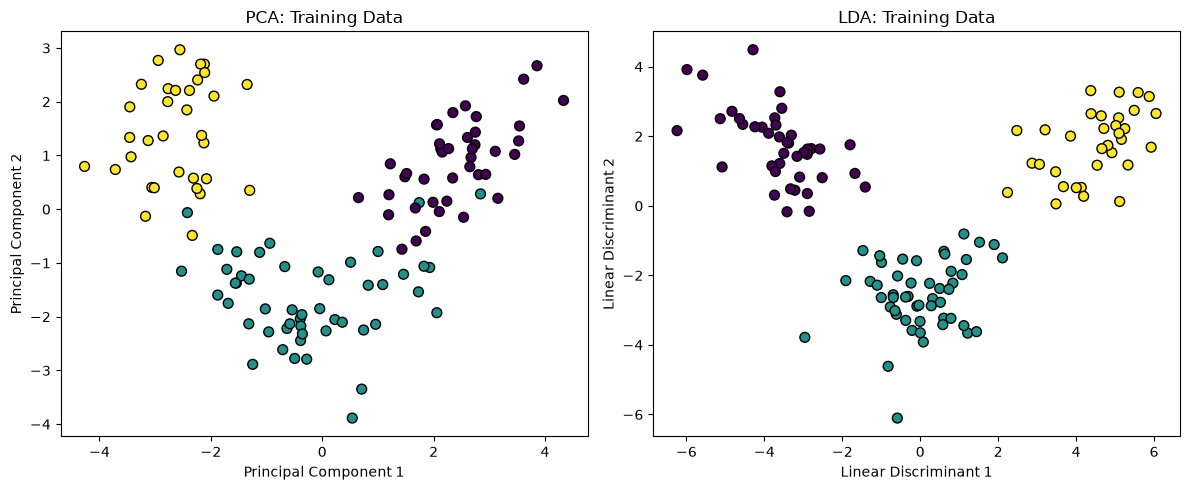

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('PCA: Training Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.subplot(1, 2, 2)
plt.scatter(X_train_lda[:, 0], X_train_lda[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('LDA: Training Data')
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.tight_layout()
plt.show()


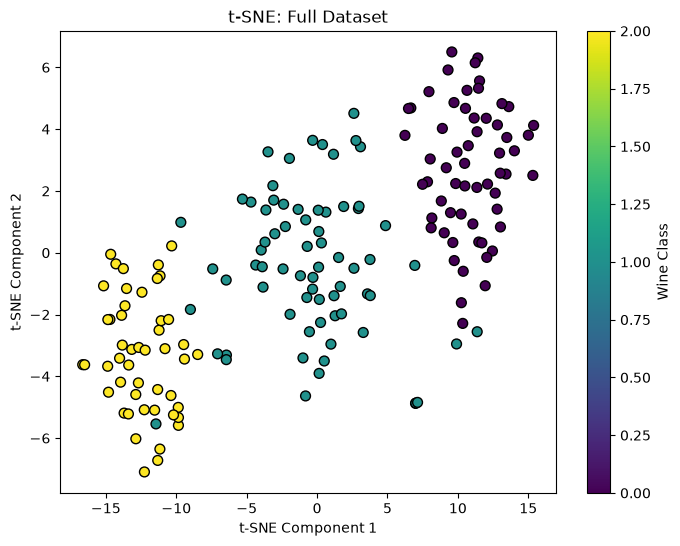

In [12]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=1,perplexity=30)

X_scaled = scaler.transform(X)

full_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(full_tsne[:, 0], full_tsne[:, 1], c=y, cmap='viridis', edgecolor='k', s=50)
plt.title('t-SNE: Full Dataset')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.colorbar(label='Wine Class')
plt.show()

Based on the results, I would use LDA and T-sne for visualization and use pca for classification because the testing accuracy is higher.

## Exercise 4 (9 points)

A hospital builds a classifier to detect a rare disease that affects 5% of patients. The model achieves 95% accuracy on a test set that has the same 5% prevalence.

**(a)** What is the *null accuracy* in this problem? Explain why a 95% accuracy might say nothing about the usefulness of the model.

**(b)** Name two metrics (computed from the confusion matrix) that would be more informative here, give their formulas, and explain what each tells you about the rare class.

**(c)** A dataset has $n = 1000$ observations, of which 50 are positive. Compute the "balanced" class weights $w_j = \frac{n}{k\, n_j}$ for each class and explain what they accomplish.

*Write your answer here.*
(a) because only 5% of the data is classified as the rare disease a 95% accuracy does not mean the model classified the rare disease well only that it classified 95% of the dataset correctly.

(b) recall and precision would do better here. recall is (true positives)/(true positive + false negatives), recall tells us the amount of rare diseases we actually classified right. precision is (true positive)/(true positives + false positives). precision tells us the amount of correctly classified rare diseases out of the one we predicted to have the disease.

(c) w1 = 1000/2(50) = 10, w0 = 1000/2(950) = .5263. a higher weight is given to the minority class which makes the model focus more on the minority.

## Exercise 5 (5 points)

A fraud-detection team assigns a cost of $C_{FP} = 2$ to every false positive (an unnecessary review) and $C_{FN} = 10$ to every false negative (a missed fraud). Assuming the model produces well-calibrated probabilities, which statement is **TRUE**?

**A.** The cost-optimal cutoff is $c^* = C_{FN}/(C_{FP}+C_{FN}) \approx 0.83$, so only very confident predictions should be flagged as fraud.

**B.** The cost-optimal cutoff is $c^* = C_{FP}/(C_{FP}+C_{FN}) \approx 0.17$, so transactions with predicted fraud probability above about 0.17 should be flagged.

**C.** The cost-optimal cutoff is 0.5 regardless of the costs, because the costs only matter during training.

**D.** ROC-AUC will change if we move the cutoff from 0.5 to 0.17, so ROC-AUC should be used to pick the cutoff.

Select one answer and justify it in one or two sentences.

*Write your answer here.*

(b) because false negatives are more costly the cutoff should be lower

## Exercise 6: (30 points)

In this exercise you will study classification on imbalanced data. Generate the data with:

```python
from sklearn.datasets import make_classification
X, y = make_classification(n_samples = 5000, n_features = 10, n_informative = 5,
                           weights = [0.92, 0.08], flip_y = 0.03, class_sep = 0.8,
                           random_state = 1)
```

Treat class 1 as the positive (event) class.

**(a)** Split the data into training (60%), validation (20%) and test (20%) sets using stratified sampling (`random_state = 1`). Report the proportion of positives in each set and the *null accuracy* on the test set.

**(b)** Fit a `RandomForestClassifier(n_estimators = 200, max_depth = 5, random_state = 1)` on the training set. On the test set (default cutoff 0.5) report accuracy, recall, precision, F1, balanced accuracy, ROC-AUC and PR-AUC.

**(c)** Refit the random forest with `class_weight = 'balanced'`. Report the same metrics on the test set (cutoff 0.5) and compare with (b).

**(d)** Suppose $C_{FP} = 1$ and $C_{FN} = 5$. Using the **baseline** model from (b), compute the total cost on the validation set for cutoffs from 0.01 to 0.99 (step 0.01), plot total cost vs. cutoff, and choose the cutoff with the smallest cost. Also compute the theoretical cutoff $c^* = C_{FP}/(C_{FP}+C_{FN})$.

**(e)** Apply the chosen cutoff to the test set and report the confusion matrix and total test cost. Compare it with the total cost of (i) the baseline model at cutoff 0.5, (ii) the "flag nobody" strategy and (iii) the "flag everybody" strategy.

**(f)** In 3–4 sentences, summarize what you learned: which approach (class weights vs. moving the cutoff) worked better in terms of cost, and why accuracy alone would have been misleading.

In [13]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples = 5000, n_features = 10, n_informative = 5,
                           weights = [0.92, 0.08], flip_y = 0.03, class_sep = 0.8,
                           random_state = 1)

In [14]:
x_train, x_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=1)

x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=1)

print("Training positive class proportion:", y_train.mean())
print("Validation positive class proportion:", y_val.mean())
print("Testing positive class proportion:", y_test.mean())

print("null accuracy:", max(y_train.mean(), 1 - y_train.mean()))

Training positive class proportion: 0.091
Validation positive class proportion: 0.091
Testing positive class proportion: 0.091
null accuracy: 0.909


In [15]:
from sklearn.metrics import recall_score,precision_score, f1_score, balanced_accuracy_score, roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=1)

rf_model.fit(x_train, y_train)

y_prob = rf_model.predict_proba(x_test)[:, 1]
y_pred = rf_model.predict(x_test)

print('accuracy_score:', accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))
print("Average precision:", average_precision_score(y_test, y_prob))

accuracy_score: 0.937
Recall: 0.3076923076923077
Precision: 1.0
F1-score: 0.47058823529411764
Balanced accuracy: 0.6538461538461539
ROC AUC: 0.904906974213905
Average precision: 0.7783683441054746


In [16]:
rf_model_balanced = RandomForestClassifier(n_estimators=200, max_depth=5, class_weight='balanced', random_state=1)

rf_model_balanced.fit(x_train, y_train)

y_prob_balanced = rf_model_balanced.predict_proba(x_test)[:, 1]
y_pred_balanced = rf_model_balanced.predict(x_test)

print('accuracy_score:', accuracy_score(y_test, y_pred_balanced))
print("Recall:", recall_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced))
print("F1-score:", f1_score(y_test, y_pred_balanced))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred_balanced))
print("ROC AUC:", roc_auc_score(y_test, y_prob_balanced))
print("Average precision:", average_precision_score(y_test, y_prob_balanced))

accuracy_score: 0.887
Recall: 0.7692307692307693
Precision: 0.43209876543209874
F1-score: 0.5533596837944664
Balanced accuracy: 0.834010324109334
ROC AUC: 0.8966259263288966
Average precision: 0.7539321051404068


the model with balanced did better at predicting the minority class as we can see as it has higher recall

Optimal cutoff: 0.14
Best cost: 164
theoretical best cost: 0.16666666666666666


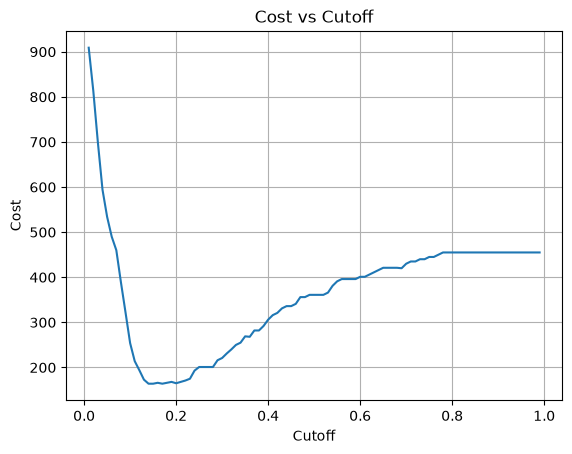

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

y_val_prob = rf_model.predict_proba(x_val)[:, 1]

cutoffs = np.arange(0.01, 1.0, 0.01)

costs = []

for cutoff in cutoffs:
    y_val_pred = (y_val_prob >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, y_val_pred, labels=[0, 1]).ravel()
    cost =  fp + 5 * fn
    costs.append(cost)
    
optimal_cutoff = cutoffs[np.argmin(costs)]
best_cost = min(costs)

print("Optimal cutoff:", optimal_cutoff)
print("Best cost:", best_cost)
print('theoretical best cost:', 1/(1+5))

plt.plot(cutoffs, costs)
plt.xlabel("Cutoff")
plt.ylabel("Cost")
plt.title("Cost vs Cutoff")
plt.grid(True)
plt.show()

In [21]:
y_test_prob = rf_model.predict_proba(x_test)[:, 1]
y_test_pred = (y_test_prob >= optimal_cutoff).astype(int)

print(confusion_matrix(y_test, y_test_pred))

#total test cost
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred, labels=[0, 1]).ravel()
print("Total test cost:", fp + 5 * fn)

# (i) baseline model 
y_test_pred_baseline = (y_test_prob >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred_baseline, labels=[0, 1]).ravel()

baseline_cost = fp + 5 * fn
print("Baseline model cost:", baseline_cost)

#(ii) flag nobody strategy
y_test_pred_flag_nobody = np.zeros(len(y_test), dtype=int)

tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred_flag_nobody, labels=[0, 1]).ravel()

flag_nobody_cost = fp + 5 * fn
print("Flag nobody strategy cost:", flag_nobody_cost)

# (iii) flag everybody strategy
y_test_pred_flag_everybody = np.ones(len(y_test), dtype=int)

tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred_flag_everybody, labels=[0, 1]).ravel()

flag_everybody_cost = fp + 5 * fn
print("Flag everybody strategy cost:", flag_everybody_cost)


[[855  54]
 [ 20  71]]
Total test cost: 154
Baseline model cost: 315
Flag nobody strategy cost: 455
Flag everybody strategy cost: 909


In [25]:
y_test_prob_balanced = rf_model_balanced.predict_proba(x_test)[:, 1]
y_test_pred_balanced = (y_test_prob_balanced >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred_balanced, labels=[0, 1]).ravel()

balanced_cost = fp + 5 * fn
print("Balanced model cost:", balanced_cost)

Balanced model cost: 197


comparing all the total costs shows that moving the cutoff worked better at lowering the cost. Both models did better than the baseline model in terms of cost. using only accuracy would have been misleading because the dataset is imbalanced. as explained earlier a model can have a high accuracy but that does not mean it is good at classifying the minority class.